## CPSC 425 HW1

Jaden Majid

jadenvm

94916335


In [24]:

from PIL import Image
import numpy as np
import math
from scipy import signal
import cv2
from IPython.display import display
import matplotlib.pyplot as plt

## Part 2

### Part 2.1

In [25]:
def boxfilter(x):
    assert x%2==1
    return (1/x**2)*np.ones((x,x))

print("n=3")
print(boxfilter(3))
print("n=5")
print(boxfilter(5))
try:
    boxfilter(4)
except AssertionError:
    print("n=4 threw assert error")
    pass

n=3
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
n=5
[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]
n=4 threw assert error


### Part 2.2

Write a Python function, ‘gauss1d(sigma)’, that returns a 1D Gaussian filter for a given value of sigma.
The filter should be a 1D array with length 6 times sigma rounded up to the next odd integer. 
Each value of the filter can be computed from the Gaussian function, $exp(- x^2 / (2*sigma^2))$, 
where x is the distance of an array value from the center. 
This formula for the Gaussian ignores the constant factor. 
Therefore, you should normalize the values in the filter so that they sum to 1.
HINTS: For efficiency and compactness, it is best to avoid ‘for’ loops in Python. 
One way to do this is to first generate a 1D array of values for x, and 
map this array through the density function. Suppose you want to generate a 1D filter from 
a zero-centered Gaussian with a sigma of 1.6. The filter length would be odd(1.6*6)=11. 
You then generate a 1D array of x values [-5 -4 -3 -2 -1 0 1 2 3 4 5] and 
pass the 1D array through the given density function $exp(- x^2 / (2*sigma^2))$.

Show the filter values produced for sigma values of 0.3, 0.5, 1, and 2. 

In [26]:
def gauss1d(sigma):
    n = math.ceil(6 * sigma) + 1
    if n % 2 == 0:
        n = math.ceil(6 * sigma)
    
    x = np.arange(n) - (n-1)/2 
    unnormalized = np.exp(-1*(x**2) / (2*sigma**2))
    return unnormalized/np.sum(unnormalized)

for sigma in [0.3, 0.5, 1, 2]:
    print(f"gauss1d for {sigma}(len={len(gauss1d(sigma))}):")
    print(gauss1d(sigma))
    print()

gauss1d for 0.3(len=3):
[0.00383626 0.99232748 0.00383626]

gauss1d for 0.5(len=3):
[0.10650698 0.78698604 0.10650698]

gauss1d for 1(len=7):
[0.00443305 0.05400558 0.24203623 0.39905028 0.24203623 0.05400558
 0.00443305]

gauss1d for 2(len=13):
[0.0022182  0.00877313 0.02702316 0.06482519 0.12110939 0.17621312
 0.19967563 0.17621312 0.12110939 0.06482519 0.02702316 0.00877313
 0.0022182 ]



### Part 2.3

Create a Python function ‘gauss2d(sigma)’ that returns a 2D Gaussian filter for a given value of sigma.
The filter should be a 2D array. Remember that a 2D Gaussian can be formed by convolution of a 1D Gaussian
with its transpose. You are required to use the function ‘convolve2d’ in the Scipy Signal Processing 
toolbox to do the convolution. You will need to provide signal.convolve2d with a 2D array. To convert 
a 1D array, f, to a 2D array f, of the same size you use ‘f = f[np.newaxis]’.

Show the 2D Gaussian filter for sigma values of 0.5 and 1. 

In [27]:
def gauss2d(sigma):
    return np.outer(gauss1d(sigma), gauss1d(sigma))

for sigma in [0.5, 1]:
    print(f"gauss2d for {sigma}:")
    print(gauss2d(sigma))
    print()

gauss2d for 0.5:
[[0.01134374 0.08381951 0.01134374]
 [0.08381951 0.61934703 0.08381951]
 [0.01134374 0.08381951 0.01134374]]

gauss2d for 1:
[[1.96519161e-05 2.39409349e-04 1.07295826e-03 1.76900911e-03
  1.07295826e-03 2.39409349e-04 1.96519161e-05]
 [2.39409349e-04 2.91660295e-03 1.30713076e-02 2.15509428e-02
  1.30713076e-02 2.91660295e-03 2.39409349e-04]
 [1.07295826e-03 1.30713076e-02 5.85815363e-02 9.65846250e-02
  5.85815363e-02 1.30713076e-02 1.07295826e-03]
 [1.76900911e-03 2.15509428e-02 9.65846250e-02 1.59241126e-01
  9.65846250e-02 2.15509428e-02 1.76900911e-03]
 [1.07295826e-03 1.30713076e-02 5.85815363e-02 9.65846250e-02
  5.85815363e-02 1.30713076e-02 1.07295826e-03]
 [2.39409349e-04 2.91660295e-03 1.30713076e-02 2.15509428e-02
  1.30713076e-02 2.91660295e-03 2.39409349e-04]
 [1.96519161e-05 2.39409349e-04 1.07295826e-03 1.76900911e-03
  1.07295826e-03 2.39409349e-04 1.96519161e-05]]



### Part 2.4

(a) Write a function ‘convolve2d_manual(array, filter)’ that takes in an image (stored in `array`) and a filter, and performs convolution to the image with zero paddings (thus, the image sizes of input and output are the same). Both input variables are in type `np.float32`. Note that for this implementation you should use two for-loops to iterate through each neighbourhood.


In [28]:

def convolve2d_manual(array, filter):
    filter = np.flip(filter, axis=(0,1)) # flip because filter is being convolved
    (filter_width, _) = filter.shape
    (height, width) = array.shape
    output = np.zeros_like(array, dtype=np.float32)
    padded = np.pad(array, (filter_width//2,filter_width//2))

    # index in terms of output array
    for i in range(height):
        for j in range(width):
            output[i, j] = np.sum(padded[i:i+filter_width, j:j+filter_width] * filter, axis=(0,1))
    return output


(b) Write a function ‘gaussconvolve2d_manual(array,sigma)’ that applies Gaussian convolution to a 2D array for the given value of sigma. The result should be a 2D array. Do this by first generating a filter with your ‘gauss2d’, and then applying it to the array with ‘convolve2d_manual(array, filter)’


In [29]:
def gaussconvolve2d_manual(array, sigma):
    return convolve2d_manual(array, gauss2d(sigma))

(c) Apply your ‘gaussconvolve2d_manual’ with a sigma of 3 on the image of the dog. Download the image (right-click on an image in your browser and choose “save as”). Load this image into Python, convert it to a greyscale, Numpy array and run your ‘gaussconvolve2d_manual’ (with a sigma of 3). Note, as mentioned in class, for any image filtering or processing operations converting image to a double array format will make your life a lot easier and avoid various artifacts. Once all processing operations are done, you will need to covert the array back to unsigned integer format for storage and display. 

In [30]:

dog_im = Image.open('dog.jpg')
print("original dimensions")
print(dog_im.size, dog_im.mode, dog_im.format)
dog_im = dog_im.convert('L')

convolved_array = gaussconvolve2d_manual(np.asarray(dog_im), 3)
dog_im_processed = Image.fromarray(convolved_array)
print("final dimensions")
print(dog_im_processed.size, dog_im_processed.mode, dog_im_processed.format)
dog_im_processed.convert('L').save("dog_gauss_blur.jpg")

original dimensions
(410, 361) RGB JPEG
final dimensions
(410, 361) F None


(d) Use PIL to show both the original and filtered images.  

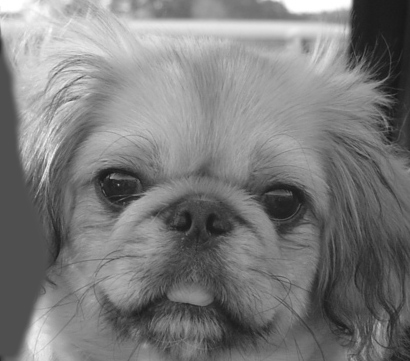

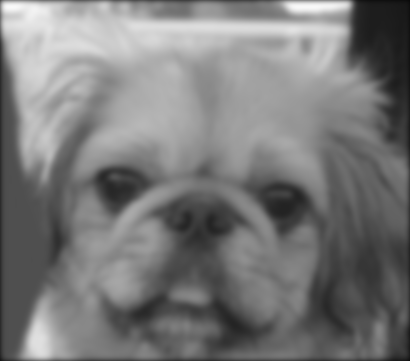

In [31]:
display(dog_im.convert('RGB'))
display(dog_im_processed.convert('RGB'))

### Part 2.5
(a) Write a function ‘gaussconvolve2d_scipy(array,sigma)’ that applies Gaussian convolution to a 2D array for the given value of sigma. The result should be a 2D array. Do this by first generating a filter with your ‘gauss2d’, and then applying it to the array with signal.convolve2d(array,filter,'same'). The ‘same’ option makes the result the same size as the image.

The Scipy Signal Processing toolbox also has a function ‘signal.correlate2d’. Applying the filter ‘gauss2d’ to the array with signal.correlate2d(array,filter,'same') produces the same result as with signal.convolve2d(array,filter,'same'). Why does Scipy have separate functions ‘signal.convolve2d’ and ‘signal.correlate2d’? HINT: Think of a situation in which ‘signal.convolve2d’ and ‘signal.correlate2d’ (with identical arguments) produce different results.

In [32]:
def gaussconvolve2d_scipy(array,sigma):
    filter = gauss2d(sigma)
    return signal.correlate2d(array, filter, 'same')


#### ANSWER
Scipy has correlate and convolve because correlation and convolution only 
produce the same result when filters are equal to their 180 degree rotation


(b) Apply your ‘gaussconvolve2d_scipy’ with a sigma of 3 on the image of the dog again. Follow instructions in part 4c for saving and loading the image.

In [33]:
dog_im = Image.open('dog.jpg')
print("original dimensions")
print(dog_im.size, dog_im.mode, dog_im.format)
dog_im = dog_im.convert('L')

convolved_array_scipy = gaussconvolve2d_scipy(np.asarray(dog_im), 3)
dog_im_processed_scipy = Image.fromarray(convolved_array_scipy)
print("final dimensions")
print(dog_im_processed_scipy.size, dog_im_processed_scipy.mode, dog_im_processed_scipy.format)
dog_im_processed_scipy.convert('L').save("dog_gauss_blur.jpg")

original dimensions
(410, 361) RGB JPEG
final dimensions
(410, 361) F None


(c) Use PIL to show both the original and filtered images. 

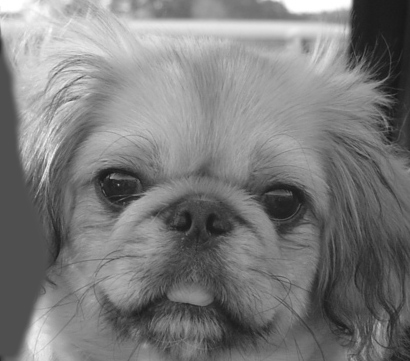

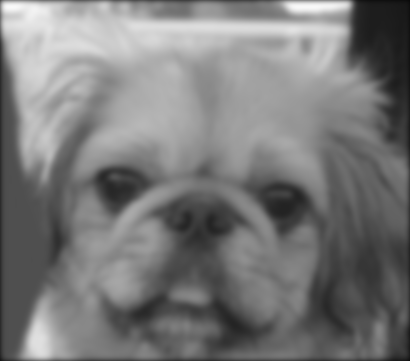

images are not equal!


In [34]:
display(dog_im.convert('RGB'))
display(dog_im_processed_scipy.convert('RGB'))

print("images are equal!" if (convolved_array_scipy == convolved_array).all() else "images are not equal!")

###  Part 2.6

Experiment on how much time it takes to convolve the dog image above using your convolution implementation ‘gaussconvolve2d_manual’ and the scipy implementation ‘gaussconvolve2d’. Compare and comment on the performance using a sigma of 10.0. HINT: The following code shows you how to time a function. Also, depending on efficency of your implementation you may see different runtimes here compared to the scipy implementation, that's OK. The key is thinking and explaining why you get a certain result. 

In [35]:
import time

dog_im_array = np.asarray(dog_im)
part26_filter = gauss2d(10.0)

t0 = time.time() # start timestamp
gaussconvolve2d_manual(dog_im_array, 10.0)
duration_manual = time.time() - t0 # duration in seconds
print(f"manual took {duration_manual:0.3f}s")

t0 = time.time() # start timestamp
gaussconvolve2d_scipy(dog_im_array, 10.0)
duration_scipy = time.time() - t0 # duration in seconds
print(f"scipy took {duration_scipy:0.3f}s")

print(f"scipy had a {duration_manual/duration_scipy:0.2}x speedup compared to the manual implementation")


manual took 0.514s
scipy took 0.309s
scipy had a 1.7x speedup compared to the manual implementation


#### Answer
The performance of manual is marginally worse than scipy. Scipy is 1.7x faster. 

I belive this may be because I copy the array when I pad it, which takes time to allocate new memory for the image,
then copy the original image to the new padded array.

The original performance difference was nearly 400x, because I was using 4 nested for loops.

I went back to the manual implementation to remove the two hottest for loops with a numpy hamard product
then a numpy sum call. Which improved performance from ~100+ seconds to 0.5 seconds.

### Part 2.7
Convolution with a 2D Gaussian filter is not the most efficient way to perform Gaussian convolution on an image. In a few sentences, explain how this could be implemented more efficiently taking advantage of separability and why, indeed, this would be faster. NOTE: It is not necessary to implement this. Just the explanation is required. Your answer will be graded for clarity. 

#### Answer

To take advantage of separability we could replace the 2d filter with two 1d convolutions on the original matrix.

For some filter $F=cr^T$, the convolution $Y = F*X$ can be accomplished by performing $Y_1 = c *_\text{col} X, Y = r^T*_\text{row}Y_1$

This would improve the big O from $O(whn^2)$ to $O(whn)$ for an $(n,n)$ filter.


## Part 3

 Gaussian filtering produces a low-pass (blurred) filtered version of an image. Consequently, the difference between the original and the blurredlow-pass filtered counterpart results in a high-pass filtered version of the image. As defined in the original ACM Siggraph 2006 paper a hybrid image is the sum of a low-pass filtered version of the one image and a high-pass filtered version of a second image. There is a free parameter, which can be tuned for each image pair, which controls how much high frequency to remove from the first image and how much low frequency to leave in the second image. This is called the``cutoff-frequency''. In the paper it is suggested to use two cutoff frequencies (one tuned for each image) and you are free to try that, as well. In the starter code, the cutoff frequency is controlled by changing the standard deviation of the Gausian filter used in constructing the hybrid images.

We provide you with pairs of aligned images which can be merged reasonably well into hybrid images. The alignment is important because it affects the perceptual grouping (read the paper for details). We encourage you to create additional examples (e.g. change of expression, morph between different objects, change over time, etc.). See the hybrid images project page for some inspiration. 

### Part 3.1

Choose an appropriate sigma and create a blurred version of the one of the paired images. For this to work you will need to choose a relatively large sigma and filter each of the three color channels (RGB) separately, then compose the channels back to the color image to display. Note, you should use the same sigma for all color channels. 

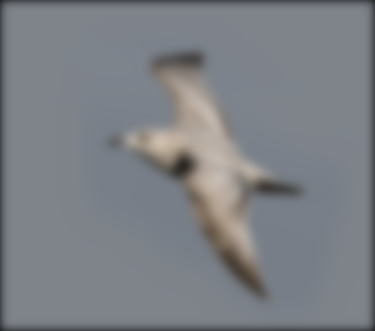

In [36]:
def get_lf(fp, sigma=5.0):
    a_tensor = np.asarray(Image.open(fp))
    a_low_freq_tensor = np.zeros_like(a_tensor)
    for layer_idx in range(3):
        a_low_freq_tensor[:,:,layer_idx] = gaussconvolve2d_scipy(a_tensor[:,:,layer_idx], sigma)
    return a_low_freq_tensor

def get_hf(fp, sigma=5.0):
    im = np.asarray(Image.open(fp)).astype(np.float32)
    return (im - get_lf(fp, sigma).astype(np.float32)).astype(np.uint8)

def get_combined(fp0, fp1, sigma=5.0):
    combined = get_lf(fp0, sigma).astype(np.float32) + get_hf(fp1, sigma)
    return np.clip(combined, 0, 255).astype(np.uint8)

def get_combined_im(fp0,fp1, sigma=5.0):
    return Image.fromarray(get_combined(fp0,fp1, sigma))


display(Image.fromarray(get_lf("4a_bird.bmp")))

### Part 3.2

Choose an appropriate sigma (it is suggested to use the same as above) and create a high frequency version of the second from the two the paired images. Again you will operate on each of the color channels separately and use same sigma for all channels. High frequency filtered image is obtained by first computing a low frequency Gaussian filtered image and then subtracting it from the original. The high frequency image is actually zero-mean with negative values so it is visualized by adding 128 (if you re-scaled the original image to the range between 0 and 1, then add 0.5 for visualization). In the resulting visualization illustrated below, bright values are positive and dark values are negative. 

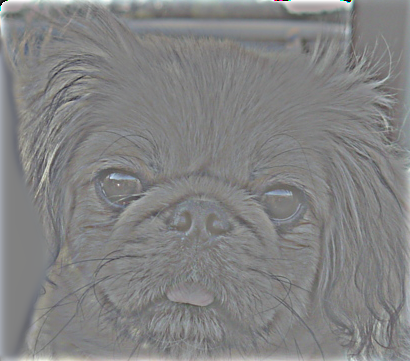

In [37]:
display(Image.fromarray(get_hf("0b_dog.bmp")+128))

### Part 3.3

Now simply add the low and high frquency images (per channel). Note, the high frequency image that you add,should be the originally computed high friequency image (without adding 128; this addition is only done for visualizationes in the part above). You may get something like the following as a result: 

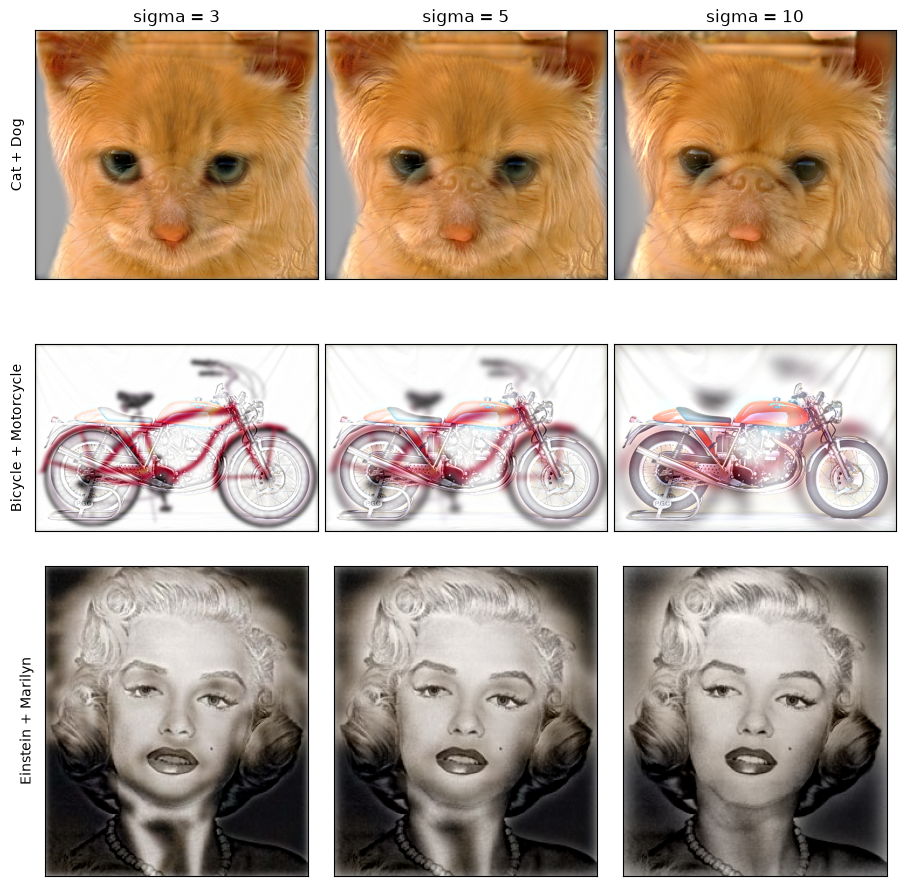

In [15]:
def get_lf(fp, sigma=5.0):
    image_array = np.asarray(Image.open(fp)).astype(np.float32)
    low_frequency = np.zeros_like(image_array, dtype=np.float32)
    for channel_index in range(image_array.shape[2]):
        low_frequency[:, :, channel_index] = gaussconvolve2d_scipy(
            image_array[:, :, channel_index], sigma
        )
    return low_frequency


def get_hf(fp, sigma=5.0):
    image_array = np.asarray(Image.open(fp)).astype(np.float32)
    return image_array - get_lf(fp, sigma)


def get_combined(fp0, fp1, sigma=5.0):
    combined = get_lf(fp0, sigma) + get_hf(fp1, sigma)
    return np.clip(combined, 0, 255).astype(np.uint8)


def get_combined_im(fp0, fp1, sigma=5.0):
    return Image.fromarray(get_combined(fp0, fp1, sigma))


photo_pairs = [
    ("Cat + Dog", "0a_cat.bmp", "0b_dog.bmp"),
    ("Bicycle + Motorcycle", "1a_bicycle.bmp", "1b_motorcycle.bmp"),
    ("Einstein + Marilyn", "2a_einstein.bmp", "2b_marilyn.bmp"),
]
sigmas = [3, 5, 10]

fig, axes = plt.subplots(
    len(photo_pairs), len(sigmas), figsize=(9, 9), squeeze=False
)

for row_index, (pair_name, low_frequency_file, high_frequency_file) in enumerate(photo_pairs):
    for column_index, sigma in enumerate(sigmas):
        axes[row_index, column_index].imshow(
            get_combined_im(low_frequency_file, high_frequency_file, sigma)
        )
        axes[row_index, column_index].set_xticks([])
        axes[row_index, column_index].set_yticks([])
        if row_index == 0:
            axes[row_index, column_index].set_title(f"sigma = {sigma}")
    axes[row_index, 0].set_ylabel(pair_name, rotation=90, labelpad=8)

fig.tight_layout(pad=0.5, w_pad=0.5, h_pad=0.5)
plt.show()

## Part 4: Playing with Different Denoising Filters (9 points)

In this question, you are given two images affected by Gaussian noise and speckle noise box_gauss.png and box_speckle.png. You will apply Gaussian filter, bilateral filter, and median filter respectively to denoise the images. Use the existing implementation in the OpenCV library ‘cv2’. Specifically, you will use the functions ‘cv2.GaussianBlur’, ‘cv2.bilateralFilter’, and ‘cv2.medianBlur’. Please consult the OpenCV documentation for more details. 

### Part 4.1 (6 points)

Play with different combinations of parameters for each filter and show your best results for denoising. Include the best combinations of parameters for each filter and the corresponding resultant images in your report. Note that since you have two images and three filters, you will include a total of six denoised images. 

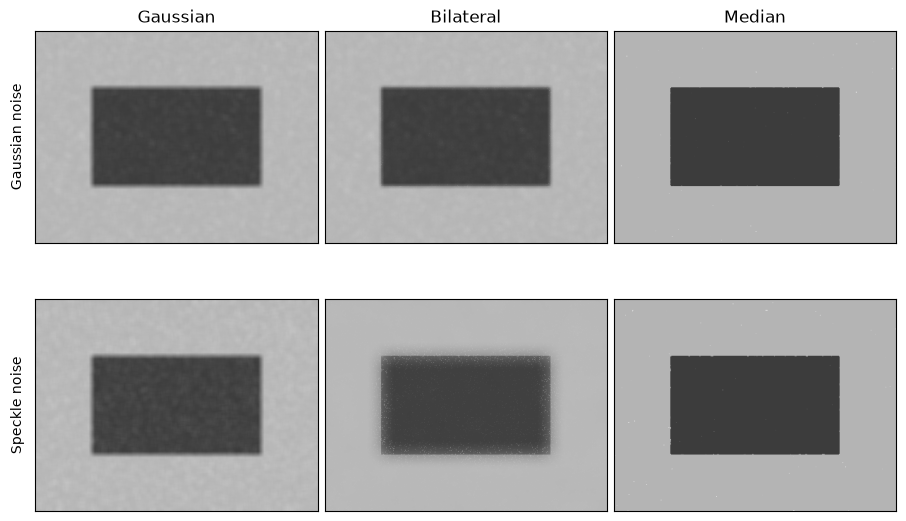

In [22]:
box_gauss_im = Image.open("box_gauss.png")
box_gauss_t = np.asarray(box_gauss_im)
box_spec_im = Image.open("box_speckle.png")
box_spec_t = np.asarray(box_spec_im)

image_sets = [
    ("Gaussian noise", box_gauss_t, [
        cv2.GaussianBlur(box_gauss_t, (9, 9), 6),
        cv2.bilateralFilter(box_gauss_t, 11, 150, 150),
        cv2.medianBlur(box_gauss_t, 3),
    ]),
    ("Speckle noise", box_spec_t, [
        cv2.GaussianBlur(box_spec_t, (9, 9), 6),
        cv2.bilateralFilter(box_spec_t, 40, 90, 90),
        cv2.medianBlur(box_spec_t, 3),
    ]),
]
filter_names = ["Gaussian", "Bilateral", "Median"]

fig, axes = plt.subplots(2, 3, figsize=(9, 6), squeeze=False)

for row_index, (image_name, original, filtered_images) in enumerate(image_sets):
    for column_index, (filter_name, filtered_image) in enumerate(
        zip(filter_names, filtered_images)
    ):
        axes[row_index, column_index].imshow(Image.fromarray(filtered_image).convert('RGB'))
        axes[row_index, column_index].set_xticks([])
        axes[row_index, column_index].set_yticks([])
        if row_index == 0:
            axes[row_index, column_index].set_title(filter_name)
    axes[row_index, 0].set_ylabel(image_name, rotation=90, labelpad=8)

fig.tight_layout(pad=0.5, w_pad=0.5, h_pad=0.5)
plt.show()

### Part 4.2 (3 points)

Now try to use the following combinations for the two images, and comment the pros and cons of using Gaussian, Bilateral, and Median filters. HINT: You might need to zoom in to see the artifacts clearly. 

Median appears to be the sharpest of the the 3, with gaussian and bilateral preserving some of the speckling. Gaussian has "smooth" artifacts while bilateral has some sharp artifacting at the edge of the box. Median blur results in some specks remaining, especially at the edges.

Gaussian appears to be the "smoothest" which is good, but the specks still bleed into their local areas.

Bilateral is also "smooth" but sharp contrasting edges introduce high frequency artifacts at borders

Median is the "best" in my opinion, but still retains some high frequency noise. 

I would use a combination of median and a gaussian if i wanted to denoise a noisy "cartoony" image like this.